In [6]:
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold

SEED = 3242
CAPACITY = 0.10

pd.set_option("display.max_columns", None)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.2

print("Python:", sys.version)
print("Environment:", sys.executable)
print("SEED:", SEED)

for package in [
    "numpy", "scipy", "pandas",
    "matplotlib", "scikit-learn", "joblib"
]:
    print(package, version(package))

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Environment: c:\Users\user\Downloads\gumar_ML_task_3\.gumar_ML_task_3\Scripts\python.exe
SEED: 3242
numpy 2.3.4
scipy 1.16.3
pandas 2.3.3
matplotlib 3.10.7
scikit-learn 1.7.2
joblib 1.5.2


In [7]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nColumns only in train:")
print(sorted(set(train.columns) - set(test.columns)))

print("\nColumns only in test:")
print(sorted(set(test.columns) - set(train.columns)))

print("\nTarget values:")
print(train["y"].value_counts())

assert train["id"].is_unique
assert test["id"].is_unique
assert set(train["id"]).isdisjoint(set(test["id"]))
assert set(train["y"].unique()) == {"yes", "no"}
assert set(train.columns) - set(test.columns) == {"duration", "y"}

display(train.head())

Train shape: (32940, 22)
Test shape: (8236, 20)

Columns only in train:
['duration', 'y']

Columns only in test:
[]

Target values:
y
no     29229
yes     3711
Name: count, dtype: int64


,id,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,tue,134,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,mon,61,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,fri,210,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,wed,72,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,wed,119,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


 Input columns and leakage . The training file has two extra columns: y and duration.
 - y is the target, so it is not an input feature.
- duration is the call length. It is unknown before the call.
  Using it would cause data leakage.
- id identifies a row. It is not a useful client feature.

The model will use the 19 features available in test.csv,
excluding id.

In [11]:
feature_columns = [
    column for column in test.columns
    if column != "id"
]

X = train[feature_columns].copy()
y = train["y"].map({"no": 0, "yes": 1})

X_test = test[feature_columns].copy()

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(cv.split(X_train, y_train))

assert X_train.index.intersection(X_holdout.index).empty
assert list(X_train.columns) == list(X_test.columns)
assert "duration" not in X_train.columns
assert "id" not in X_train.columns

print("Development training set:", X_train.shape)
print("Hold-out set:", X_holdout.shape)
print("Hidden test set:", X_test.shape)
print("Number of CV folds:", len(cv_splits))

print("\nPositive class in training:",
      f"{y_train.mean():.2%}")
print("Positive class in hold-out:",
      f"{y_holdout.mean():.2%}")

Development training set: (26352, 19)
Hold-out set: (6588, 19)
Hidden test set: (8236, 19)
Number of CV folds: 5

Positive class in training: 11.27%
Positive class in hold-out: 11.26%


In [9]:
eda = X_train.copy()
eda["y"] = y_train

class_counts = y_train.value_counts().reindex([0, 1])

class_summary = pd.DataFrame({
    "class": ["no", "yes"],
    "count": class_counts.to_numpy(),
    "percent": 100 * class_counts.to_numpy() / len(y_train)
})

display(class_summary.round(2))

majority_accuracy = (y_train == 0).mean()

print(f"Always-no accuracy: {majority_accuracy:.2%}")

missing_summary = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "NaN_count": X_train.isna().sum(),
    "unknown_count": X_train.eq("unknown").sum()
})

display(missing_summary)

sentinel_count = X_train["pdays"].eq(999).sum()

print("pdays = 999 count:", sentinel_count)
print(f"pdays = 999 share: {sentinel_count / len(X_train):.2%}")

print(
    "Rows duplicated across available features:",
    X_train.duplicated().sum()
)

,class,count,percent
0,no,23383,88.73
1,yes,2969,11.27


Always-no accuracy: 88.73%


,dtype,NaN_count,unknown_count
age,int64,0,0
job,object,0,215
marital,object,0,54
education,object,0,1130
default,object,0,5498
housing,object,0,631
loan,object,0,631
contact,object,0,0
month,object,0,0
day_of_week,object,0,0


pdays = 999 count: 25331
pdays = 999 share: 96.13%
Rows duplicated across available features: 861


,clients,yes_count,yes_rate
poutcome,,,
nonexistent,22726,1988,0.0875
failure,2705,381,0.1409
success,921,600,0.6515


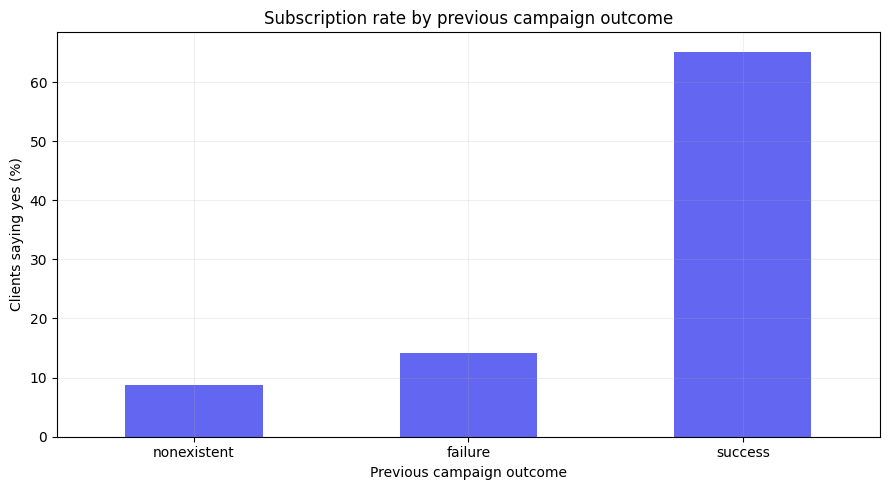

nonexistent: 8.75% said yes among 22726 clients.
failure: 14.09% said yes among 2705 clients.
success: 65.15% said yes among 921 clients.


In [10]:
previous_summary = (
    eda.groupby("poutcome")["y"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "clients",
        "sum": "yes_count",
        "mean": "yes_rate"
    })
    .sort_values("yes_rate")
)

display(previous_summary.round(4))

ax = (100 * previous_summary["yes_rate"]).plot(
    kind="bar",
    color="#6366f1",
    rot=0
)

ax.set_title("Subscription rate by previous campaign outcome")
ax.set_xlabel("Previous campaign outcome")
ax.set_ylabel("Clients saying yes (%)")

plt.tight_layout()
plt.show()

for group, row in previous_summary.iterrows():
    print(
        f"{group}: {row['yes_rate']:.2%} said yes "
        f"among {int(row['clients'])} clients."
    )

In [12]:
print("Train IDs sorted ascending:",
      train["id"].is_monotonic_increasing)

print("First 15 months in the supplied training file:")
print(train["month"].head(15).tolist())

print("\nMonth counts in the development training set:")
print(X_train["month"].value_counts())

Train IDs sorted ascending: True
First 15 months in the supplied training file:
['may', 'aug', 'aug', 'may', 'jun', 'aug', 'may', 'apr', 'jul', 'nov', 'nov', 'sep', 'aug', 'jul', 'aug']

Month counts in the development training set:
month
may    8797
jul    4615
aug    3952
jun    3381
nov    2623
apr    1678
oct     452
mar     371
sep     366
dec     117
Name: count, dtype: int64


Data limitations

The starter README says the data were split randomly
and the id values were shuffled.
We cannot use id as a time variable.
Month and day_of_week do not provide a complete date.
We should not assume that the supplied row order is chronological. 
Random validation mixes observations from historical periods.
In real use, the bank trains on the past and predicts the future.
Changes in the economy or client behaviour may reduce performance.
Our random-split results may therefore be optimistic.
The value unknown represents missing information.
The value pdays = 999 means no previous contact.
We will handle both explicitly inside the pipeline.

In [13]:
print("SEED:", SEED)

print("\nShapes:")
print("Training:", X_train.shape)
print("Hold-out:", X_holdout.shape)
print("Hidden test:", X_test.shape)

print("\nClass balance:")
display(class_summary.round(2))

print("\nMissing values:")
display(
    missing_summary.loc[
        (missing_summary["NaN_count"] > 0)
        | (missing_summary["unknown_count"] > 0)
    ]
)

print("\npdays = 999:", sentinel_count)

print("\nPrevious campaign results:")
display(previous_summary.round(4))

SEED: 3242

Shapes:
Training: (26352, 19)
Hold-out: (6588, 19)
Hidden test: (8236, 19)

Class balance:


,class,count,percent
0,no,23383,88.73
1,yes,2969,11.27



Missing values:


,dtype,NaN_count,unknown_count
job,object,0,215
marital,object,0,54
education,object,0,1130
default,object,0,5498
housing,object,0,631
loan,object,0,631



pdays = 999: 25331

Previous campaign results:


,clients,yes_count,yes_rate
poutcome,,,
nonexistent,22726,1988,0.0875
failure,2705,381,0.1409
success,921,600,0.6515


In [14]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import cross_validate

In [15]:
categorical_columns = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_columns = [
    column
    for column in X_train.select_dtypes(include="number").columns
    if column != "pdays"
]

print("Categorical:", categorical_columns)
print("Numeric:", numeric_columns)
print("Special column: pdays")


def make_preprocessor(unknown_strategy="keep"):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    pdays_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            missing_values=999,
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])

    if unknown_strategy == "keep":
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                strategy="constant",
                fill_value="unknown"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ])

    elif unknown_strategy == "mode":
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                missing_values="unknown",
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ])

    else:
        raise ValueError("Use 'keep' or 'mode'.")

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("pdays", pdays_pipeline, ["pdays"]),
        ("categorical", categorical_pipeline, categorical_columns)
    ])


def make_model(model, unknown_strategy="keep"):
    return Pipeline([
        ("preprocess", make_preprocessor(unknown_strategy)),
        ("model", model)
    ])

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Special column: pdays


In [16]:
def top_capacity_predictions(scores, capacity=CAPACITY):
    scores = np.asarray(scores)

    n_calls = max(1, int(np.floor(capacity * len(scores))))

    # Fixed random order to resolve equal scores without using labels.
    rng = np.random.default_rng(SEED)
    shuffled_indices = rng.permutation(len(scores))

    ranking = shuffled_indices[
        np.argsort(-scores[shuffled_indices], kind="stable")
    ]

    predictions = np.zeros(len(scores), dtype=int)
    predictions[ranking[:n_calls]] = 1

    return predictions


def precision_at_capacity(estimator, features, target):
    scores = estimator.predict_proba(features)[:, 1]
    selected = top_capacity_predictions(scores).astype(bool)

    return np.asarray(target)[selected].mean()


scoring = {
    "precision_at_10": precision_at_capacity,
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "accuracy": "accuracy"
}

In [17]:
candidates = {
    "Dummy": make_model(
        DummyClassifier(strategy="most_frequent")
    ),

    "Logistic": make_model(
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        )
    ),

    "Decision tree": make_model(
        DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=30,
            random_state=SEED
        )
    ),

    "Random forest": make_model(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=10,
            random_state=SEED,
            n_jobs=-1
        )
    ),

    "Logistic balanced": make_model(
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        )
    ),

    "Logistic unknown=mode": make_model(
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ),
        unknown_strategy="mode"
    )
}

In [18]:
cv_results = {}
summary_rows = []

for name, pipeline in candidates.items():
    print(f"Running: {name}", flush=True)

    result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results[name] = result

    row = {"model": name}

    for metric in scoring:
        fold_values = result[f"test_{metric}"]

        row[f"{metric}_mean"] = fold_values.mean()
        row[f"{metric}_std"] = fold_values.std(ddof=1)

    summary_rows.append(row)

    print(
        "Finished. Precision@10%:",
        f"{row['precision_at_10_mean']:.4f}",
        "+/-",
        f"{row['precision_at_10_std']:.4f}",
        flush=True
    )

comparison = (
    pd.DataFrame(summary_rows)
    .set_index("model")
    .sort_values("precision_at_10_mean", ascending=False)
)

display(comparison.round(4))

Running: Dummy
Finished. Precision@10%: 0.1116 +/- 0.0181
Running: Logistic
Finished. Precision@10%: 0.4994 +/- 0.0271
Running: Decision tree
Finished. Precision@10%: 0.4994 +/- 0.0259
Running: Random forest
Finished. Precision@10%: 0.5108 +/- 0.0217
Running: Logistic balanced
Finished. Precision@10%: 0.4987 +/- 0.0218
Running: Logistic unknown=mode
Finished. Precision@10%: 0.4991 +/- 0.0276


,precision_at_10_mean,precision_at_10_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,accuracy_mean,accuracy_std
model,,,,,,,,
Random forest,0.5108,0.0217,0.8000,0.0145,0.4741,0.0303,0.9005,0.0025
Logistic,0.4994,0.0271,0.7909,0.0135,0.4530,0.0281,0.9003,0.0019
Decision tree,0.4994,0.0259,0.7889,0.0154,0.4262,0.0248,0.8985,0.0023
Logistic unknown=mode,0.4991,0.0276,0.7908,0.0136,0.4522,0.0292,0.9003,0.0018
Logistic balanced,0.4987,0.0218,0.7911,0.0140,0.4469,0.0260,0.8254,0.0030
Dummy,0.1116,0.0181,0.5000,0.0000,0.1127,0.0001,0.8873,0.0001


,Dummy,Logistic,Decision tree,Random forest,Logistic balanced,Logistic unknown=mode
Fold 1,0.1233,0.4991,0.5066,0.5104,0.4915,0.4953
Fold 2,0.1006,0.4744,0.4706,0.4839,0.4782,0.4725
Fold 3,0.1139,0.4706,0.4744,0.4953,0.4801,0.4725
Fold 4,0.0873,0.5237,0.5294,0.5313,0.5237,0.5294
Fold 5,0.1328,0.5294,0.5161,0.5332,0.5199,0.5256


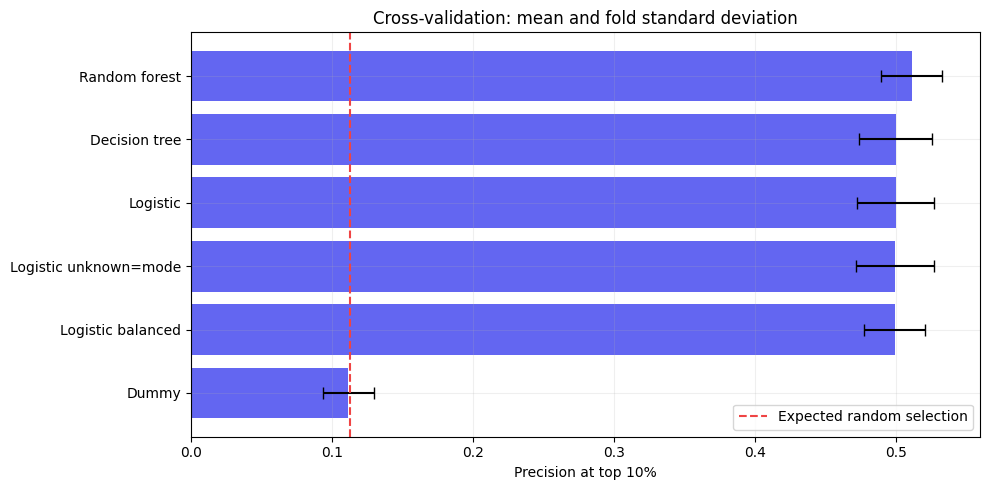

Random forest: 51.08% +/- 2.17%
Logistic: 49.94% +/- 2.71%
Decision tree: 49.94% +/- 2.59%
Logistic unknown=mode: 49.91% +/- 2.76%
Logistic balanced: 49.87% +/- 2.18%
Dummy: 11.16% +/- 1.81%


In [19]:
fold_precision = pd.DataFrame({
    name: result["test_precision_at_10"]
    for name, result in cv_results.items()
})

fold_precision.index = [
    f"Fold {i + 1}" for i in range(len(cv_splits))
]

display(fold_precision.round(4))

plot_data = comparison.sort_values("precision_at_10_mean")

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    plot_data.index,
    plot_data["precision_at_10_mean"],
    xerr=plot_data["precision_at_10_std"],
    capsize=4,
    color="#6366f1"
)

ax.axvline(
    y_train.mean(),
    color="#ef4444",
    linestyle="--",
    label="Expected random selection"
)

ax.set_xlabel("Precision at top 10%")
ax.set_title("Cross-validation: mean and fold standard deviation")
ax.legend()

plt.tight_layout()
plt.show()

for name, row in comparison.iterrows():
    print(
        f"{name}: "
        f"{row['precision_at_10_mean']:.2%} "
        f"+/- {row['precision_at_10_std']:.2%}"
    )